In [1]:
# National Snow and Ice Data Center
# a part of CIRES at the University of Colorado Boulder

# https://nsidc.org/data/user-resources/help-center/nasa-earthdata-cloud-data-access-guide#anchor-download-to-a-local-computer-from-earthdata-cloud

# run the code in modis_terra_mon_l3_glob_0.05_v061.sh -- this will download the hdf files after entering the username and password

# nano ~/.netrc has the following content

# machine urs.earthdata.nasa.gov
#   login USERNAME
#   password PASSWORD

# Go to folder with hdf files 
# cd /home/mgurazada/snowdroughts_thirst/data/snow_cover/data

# Loop over all hdf files and convert to .nc in nc_files - done only once

# for f in MOD10CM*.hdf; do
#   echo "Converting $f ..."
#   gdal_translate -of NETCDF \
#     HDF4_EOS:EOS_GRID:"$PWD/$f":MOD_CMG_Snow_5km:Snow_Cover_Monthly_CMG \
#     "nc_files/${f%.hdf}.nc"
# done

In [2]:
import re
import numpy as np
import xarray as xr
import datetime as dt
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

In [3]:
# folder containing the .nc files
nc_dir = Path("/home/mgurazada/snowdroughts_thirst/data/snow_cover/data/nc_files")

# list all .nc files
nc_files = sorted(nc_dir.glob("MOD10CM*.nc"))

def filename_to_time(path):
    """
    Extract datetime from MOD10CM filename:
    MOD10CM.AYYYYDDD. --> (year, day-of-year)
    """
    m = re.search(r"A(\d{4})(\d{3})", path.name)
    year = int(m.group(1))
    doy  = int(m.group(2))
    return dt.datetime(year, 1, 1) + dt.timedelta(doy - 1)

datasets = []

for f in nc_files:
    ds = xr.open_dataset(f)

    # rename Band1 to snow_cover
    varname = list(ds.data_vars)[1]   # 'Band1'
    ds = ds.rename({varname: "snow_cover"})

    # assign time coordinate from filename
    t = filename_to_time(f)
    ds = ds.assign_coords(time = t).expand_dims("time")

    datasets.append(ds)

# concatenate along time dimension
combined = xr.concat(datasets, dim="time")

cleaned = combined["snow_cover"].where((combined["snow_cover"] >= 0) & (combined["snow_cover"] <= 100))

# rename dataset structure back
cleaned = cleaned.to_dataset(name="snow_cover")

cleaned

<xarray.Dataset> Size: 32GB
Dimensions:     (lat: 3600, lon: 7200, time: 304)
Coordinates:
  * lat         (lat) float64 29kB -89.97 -89.92 -89.88 ... 89.88 89.93 89.98
  * lon         (lon) float64 58kB -180.0 -179.9 -179.9 ... 179.9 179.9 180.0
  * time        (time) datetime64[ns] 2kB 2000-03-01 2000-04-01 ... 2025-11-01
Data variables:
    snow_cover  (time, lat, lon) float32 32GB 100.0 100.0 100.0 ... nan nan nan

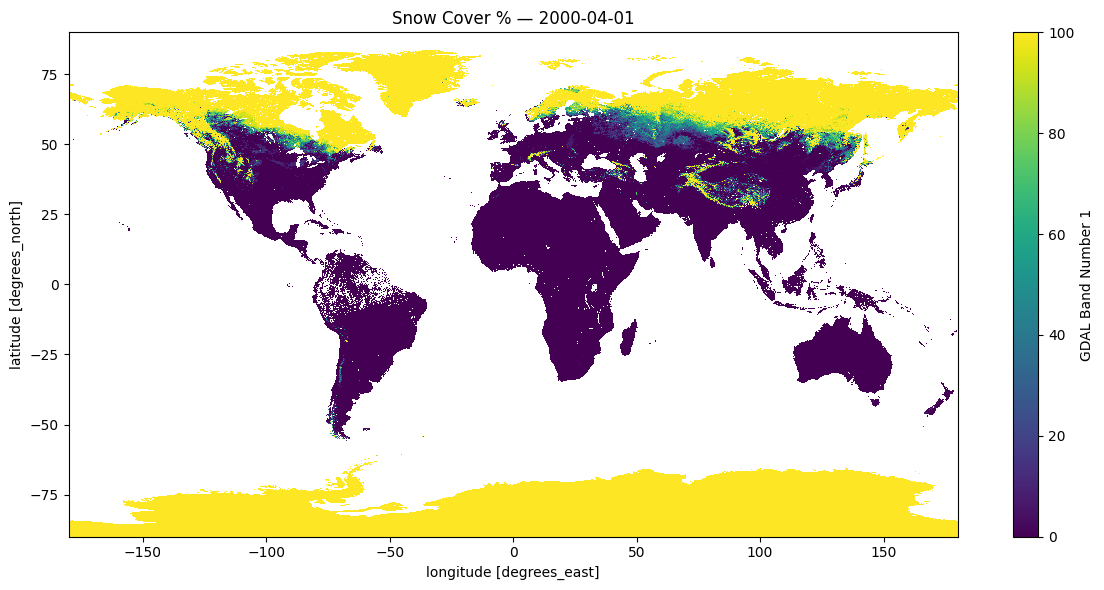

In [4]:
da = cleaned["snow_cover"].isel(time=1)

plt.figure(figsize=(12,6))
da.plot()
plt.title(f"Snow Cover % — {str(cleaned.time.values[1])[:10]}")
plt.tight_layout()
plt.show()

In [5]:
# compute monthly mean snow fraction

# snow fraction (0–1)
snow_frac = cleaned["snow_cover"] / 100.0

# monthly climatology: mean over all years for each calendar month
# result dims: month, lat, lon
monthly_clim = snow_frac.groupby("time.month").mean("time")

# Keep values as continuous fractions between 0 and 1
monthly_clim = monthly_clim.clip(0, 1)

monthly_clim

<xarray.DataArray 'snow_cover' (month: 12, lat: 3600, lon: 7200)> Size: 1GB
array([[[ 1.,  1.,  1., ...,  1.,  1.,  1.],
        [ 1.,  1.,  1., ...,  1.,  1.,  1.],
        [ 1.,  1.,  1., ...,  1.,  1.,  1.],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[ 1.,  1.,  1., ...,  1.,  1.,  1.],
        [ 1.,  1.,  1., ...,  1.,  1.,  1.],
        [ 1.,  1.,  1., ...,  1.,  1.,  1.],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[ 1.,  1.,  1., ...,  1.,  1.,  1.],
        [ 1.,  1.,  1., ...,  1.,  1.,  1.],
        [ 1.,  1.,  1., ...,  1.,  1.,  1.],
        ...,
...
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[ 1.,  1.,  1., ...,  1.,  1.,  1.],
        [ 1.,  1.,  1., ...,  1.,  1.,  1.],
        [ 1.,  1.,  1., ...,  1.,  1.,  1.],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[ 1.,  1.,  1., ...,  1.,  1.,  1.],
        [ 1.,  1.,  1., ...,  1.,  1.,  1.],
        [ 1.,  1.,  1., ...,  1.,  1.,  1.],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]]],
      shape=(12, 3600, 7200), dtype=float32)
Coordinates:
  * month    (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
  * lat      (lat) float64 29kB -89.97 -89.92 -89.88 ... 89.88 89.93 89.98
  * lon      (lon) float64 58kB -180.0 -179.9 -179.9 ... 179.9 179.9 180.0

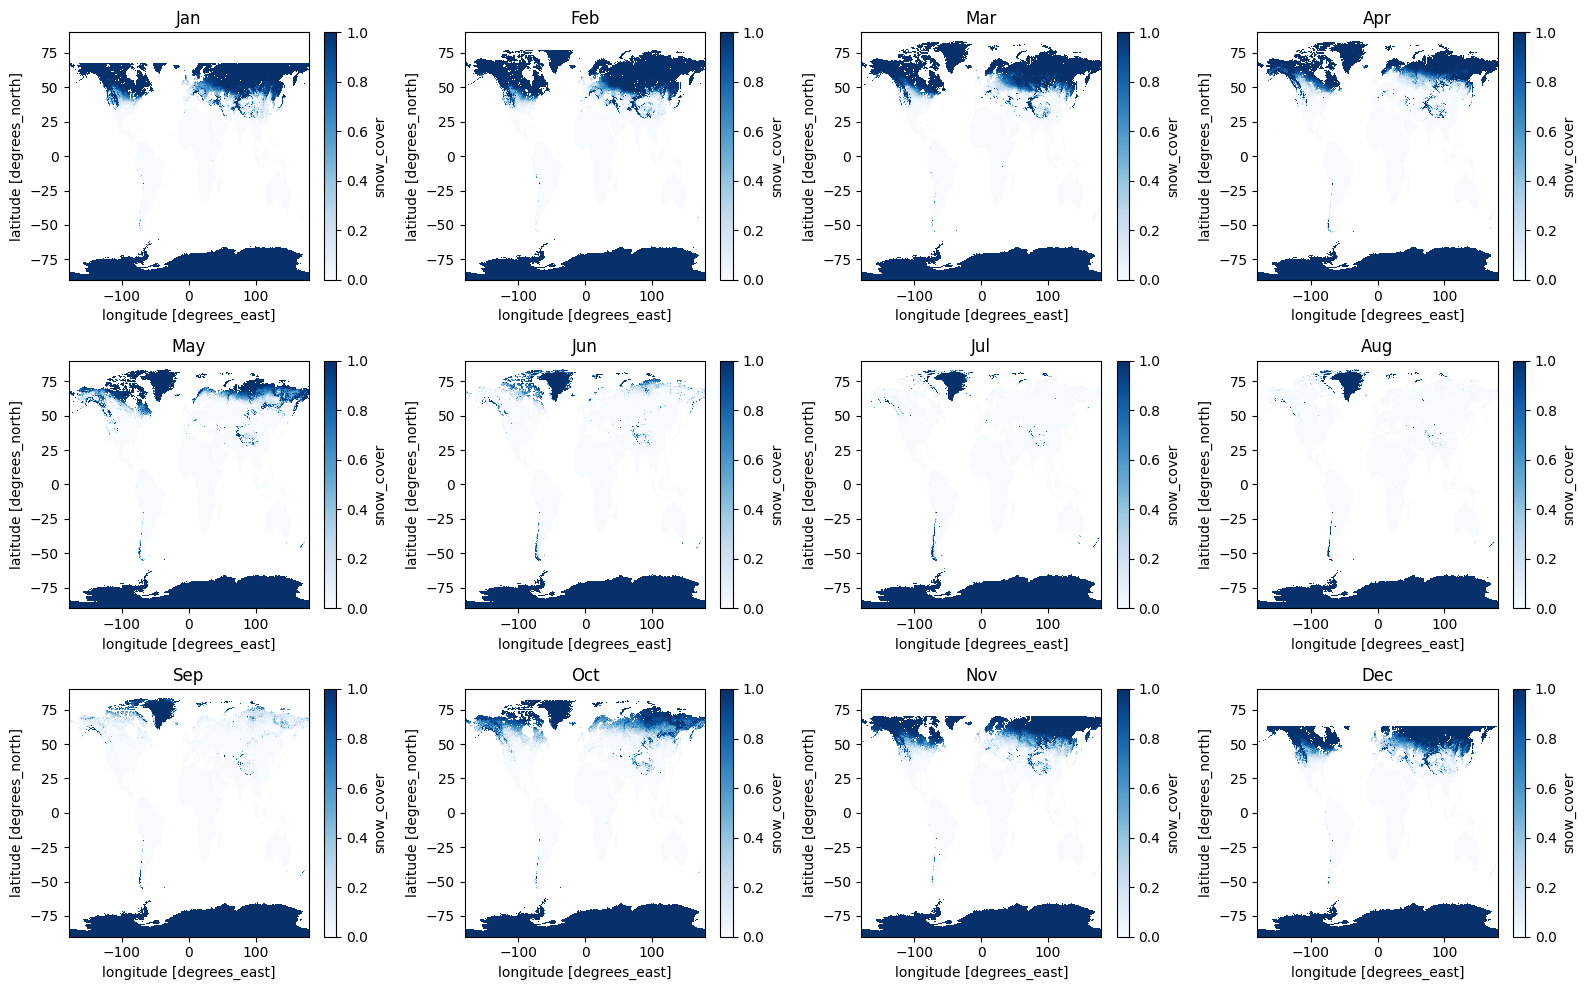

In [6]:
month_names = {
    1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr",
    5: "May", 6: "Jun", 7: "Jul", 8: "Aug",
    9: "Sep", 10: "Oct", 11: "Nov", 12: "Dec"
}

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
axes = axes.ravel()

for i, m in enumerate(monthly_clim.month.values):

    monthly_clim.isel(month=i).plot(
        ax=axes[i],
        vmin=0,
        vmax=1,
        cmap="Blues",
        add_colorbar=True
    )

    axes[i].set_title(month_names[m])

plt.tight_layout()
plt.show()

In [7]:
da = monthly_clim.isel(month=0)

lat_res = float(abs(da.lat[1] - da.lat[0]))
lon_res = float(abs(da.lon[1] - da.lon[0]))

print("Latitude resolution:", lat_res)
print("Longitude resolution:", lon_res)

Latitude resolution: 0.04999999999999716
Longitude resolution: 0.04999999999998295


In [8]:
# ============================================================
# Save fractional monthly snow-cover climatology
# ============================================================

snow_ds = monthly_clim.to_dataset(name="snow_fraction")

snow_ds["snow_fraction"].attrs["long_name"] = (
    "Monthly climatological MODIS snow-cover fraction"
)
snow_ds["snow_fraction"].attrs["units"] = "fraction (0-1)"
snow_ds["snow_fraction"].attrs["source"] = (
    "MOD10CM v6.1, processed by M. Gurazada"
)
snow_ds["snow_fraction"].attrs["note"] = (
    "Monthly mean MODIS snow-cover fraction calculated across "
    "all available years; fractional values retained without "
    "binary thresholding."
)

out_path = (
    "/home/mgurazada/snowdroughts_thirst/data/snow_cover/data/"
    "snow_mask_monthly_climatology/"
    "modis_nsidc_snow_fraction_monthly_0p05deg_v1.nc"
)

snow_ds.to_netcdf(out_path)

print("Saved:", out_path)

Saved: /home/mgurazada/snowdroughts_thirst/data/snow_cover/data/snow_mask_monthly_climatology/modis_nsidc_snow_fraction_monthly_0p05deg_v1.nc
